# BanglaBERT News Classification

In [4]:
import os, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, accuracy_score, f1_score,
                              confusion_matrix, precision_recall_fscore_support)
from sklearn.utils import class_weight
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from datasets import Dataset, concatenate_datasets

os.environ['CUDA_VISIBLE_DEVICES'] = '0'

SEED = 2018
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| CUDA:", torch.cuda.is_available())

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | CUDA: True


### Load and clean data

In [5]:
df = pd.read_json("D:/student_2k20/2007058/dataset/ittefaq.jsonl", lines=True)
df = df.dropna(subset=["Category", "Content"])

counts = df["Category"].value_counts()
df = df[df["Category"].isin(counts[counts > 1].index)].reset_index(drop=True)

print("Shape:", df.shape, "| Classes:", df["Category"].nunique())

Shape: (677818, 5) | Classes: 23


### Class distribution

In [13]:
import matplotlib.font_manager as fm
import urllib.request, os

font_path = "kalpurush.ttf"
if not os.path.exists(font_path):
    url = "https://github.com/google/fonts/raw/main/ofl/notosansbengali/NotoSansBengali%5Bwdth%2Cwght%5D.ttf"
    urllib.request.urlretrieve(url, font_path)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_22728\2769224307.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(ax.get_yticklabels(), fontproperties=bengali_font)


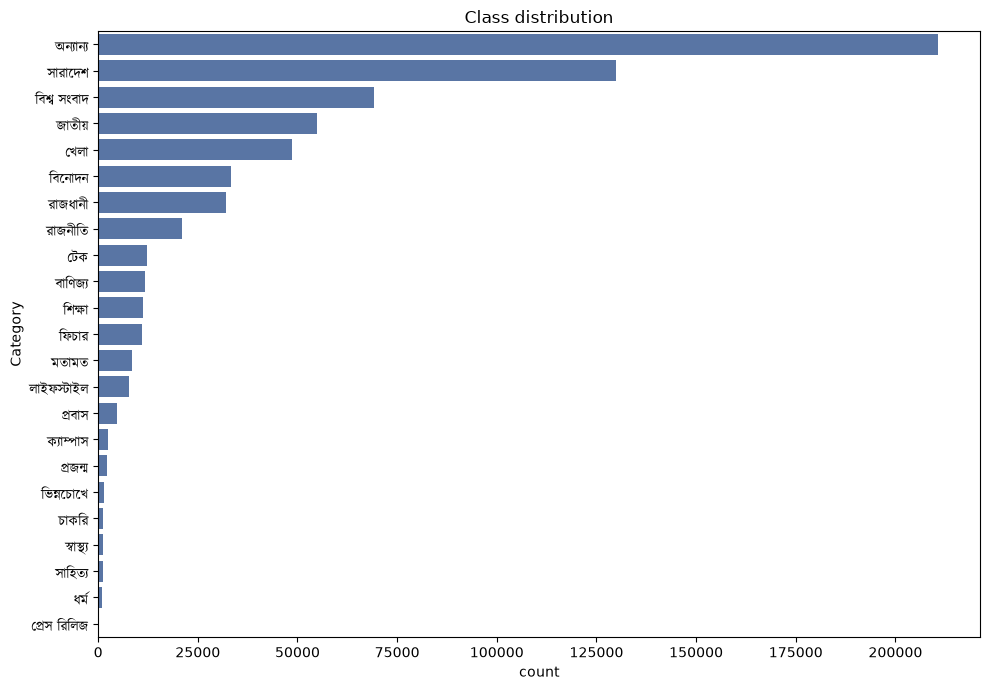

In [14]:
bengali_font = fm.FontProperties(fname=font_path)

plt.figure(figsize=(10, 7))
order = df["Category"].value_counts().index
ax = sns.countplot(y="Category", data=df, order=order, color="#4C72B0")

ax.set_yticklabels(ax.get_yticklabels(), fontproperties=bengali_font)
plt.title("Class distribution")
plt.tight_layout(); plt.show()

### Train / val / test split

In [15]:
train_text, temp_text, train_labels, temp_labels = train_test_split(
    df["Content"], df["Category"], random_state=SEED, test_size=0.2, stratify=df["Category"])
val_text, test_text, val_labels, test_labels = train_test_split(
    temp_text, temp_labels, random_state=SEED, test_size=0.2, stratify=temp_labels)

le = LabelEncoder()
train_y = le.fit_transform(train_labels)
val_y   = le.transform(val_labels)
test_y  = le.transform(test_labels)
num_labels = len(le.classes_)

print("num_labels:", num_labels)
print("train / val / test:", len(train_text), len(val_text), len(test_text))

num_labels: 23
train / val / test: 542254 108451 27113


### Model and tokenizer

In [16]:
MODEL_NAME = "csebuetnlp/banglabert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_labels).to(device)

print("Backbone prefix:", model.base_model_prefix)
print("Encoder layers :", len(model.base_model.encoder.layer))

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 21887.00it/s]
[transformers] ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missin

Backbone prefix: electra
Encoder layers : 12


### Tokenize once, cache to disk

In [17]:
MAX_LEN = 256

def to_hf(texts, labels, chunk_size=5000):
    texts, labels = list(texts), list(labels)
    parts = [Dataset.from_dict({"text": texts[i:i+chunk_size], "label": labels[i:i+chunk_size]})
             for i in range(0, len(texts), chunk_size)]
    return concatenate_datasets(parts) if len(parts) > 1 else parts[0]

raw = {"train": to_hf(train_text, train_y), "val": to_hf(val_text, val_y), "test": to_hf(test_text, test_y)}

def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN, return_token_type_ids=False)

tokenized = {}
for split, ds in raw.items():
    tokenized[split] = ds.map(tokenize_fn, batched=True, remove_columns=["text"], desc=f"Tokenizing {split}")
    tokenized[split].set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

print({k: len(v) for k, v in tokenized.items()})

Tokenizing test: 100%|██████████| 27113/27113 [00:33<00:00, 814.78 examples/s]

{'train': 542254, 'val': 108451, 'test': 27113}


In [18]:
collator = DataCollatorWithPadding(tokenizer=tokenizer, padding="longest", return_tensors="pt")

BATCH_SIZE  = 256
NUM_WORKERS = 0

train_loader = DataLoader(tokenized["train"], batch_size=BATCH_SIZE, shuffle=True,
                           collate_fn=collator, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(tokenized["val"], batch_size=BATCH_SIZE, shuffle=False,
                           collate_fn=collator, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(tokenized["test"], batch_size=BATCH_SIZE, shuffle=False,
                           collate_fn=collator, num_workers=NUM_WORKERS, pin_memory=True)

### Gradual unfreezing (backbone-agnostic)

In [19]:
def get_base(m):
    return (m.module if hasattr(m, "module") else m).base_model

STAGE2_EPOCH = 3
STAGE3_EPOCH = 6

def stage_for_epoch(e):
    if e < STAGE2_EPOCH: return 0
    if e < STAGE3_EPOCH: return 1
    return 2

def apply_freezing(m, stage):
    base = get_base(m)
    n = len(base.encoder.layer)
    for p in base.parameters():
        p.requires_grad = False
    if stage == 0:
        layers = range(n - 2, n)
    elif stage == 1:
        layers = range(n // 2, n)
    else:
        layers = range(0, n)
        for p in base.embeddings.parameters():
            p.requires_grad = True
    for i in layers:
        for p in base.encoder.layer[i].parameters():
            p.requires_grad = True

def trainable_report(m):
    tr  = sum(p.numel() for p in m.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in m.parameters())
    print(f"Trainable: {tr:,} / {tot:,} ({100*tr/tot:.1f}%)")

In [20]:
classes = np.arange(num_labels)
cw = class_weight.compute_class_weight(class_weight="balanced", classes=classes, y=train_y)
class_weights = torch.tensor(cw, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

### Optimizer, scheduler, scaler

In [21]:
EPOCHS = 10

optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)

total_steps  = EPOCHS * len(train_loader)
warmup_steps = int(0.06 * total_steps)

def warmup_linear_decay(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = LambdaLR(optimizer, lr_lambda=warmup_linear_decay)
scaler = GradScaler("cuda", enabled=(device.type == "cuda"))

In [22]:
def train_one_epoch():
    model.train()
    total_loss = 0.0
    for step, batch in enumerate(train_loader):
        input_ids      = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels         = batch["labels"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item()
        if step % 200 == 0 and step:
            print(f"  batch {step:>6,}/{len(train_loader):,}  loss {loss.item():.4f}")
    return total_loss / len(train_loader)

In [23]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss, all_logits, all_labels = 0.0, [], []
    for batch in loader:
        input_ids      = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels         = batch["labels"].to(device, non_blocking=True)
        with autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            loss = criterion(logits, labels)
        total_loss += loss.item()
        all_logits.append(logits.float().cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    logits = np.concatenate(all_logits); labels = np.concatenate(all_labels)
    preds = logits.argmax(1)
    return (total_loss / len(loader), f1_score(labels, preds, average="macro"),
            accuracy_score(labels, preds), preds, labels)

### Checkpointing

In [24]:
LAST_CKPT  = "last_checkpoint.pt"
BEST_MODEL = "best_model.pt"

def _bare(m):
    return m.module if hasattr(m, "module") else m

def save_checkpoint(epoch, best_f1, counter, history):
    torch.save({
        "epoch": epoch, "model": _bare(model).state_dict(),
        "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(), "best_f1": best_f1, "counter": counter, "history": history,
        "rng": {"torch": torch.get_rng_state(), "numpy": np.random.get_state(), "python": random.getstate()},
    }, LAST_CKPT)

def load_checkpoint():
    if not os.path.exists(LAST_CKPT):
        return None
    ckpt = torch.load(LAST_CKPT, map_location=device, weights_only=False)   # ← add this
    _bare(model).load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    torch.set_rng_state(ckpt["rng"]["torch"].cpu())
    np.random.set_state(ckpt["rng"]["numpy"])
    random.setstate(ckpt["rng"]["python"])
    return ckpt

### Training loop

In [25]:
PATIENCE = {0: 2, 1: 3, 2: 4}

start_epoch, best_f1, counter = 0, -1.0, 0
history = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}

resumed = load_checkpoint()
current_stage = -1
if resumed is not None:
    start_epoch = resumed["epoch"] + 1
    best_f1, counter, history = resumed["best_f1"], resumed["counter"], resumed["history"]
    current_stage = stage_for_epoch(start_epoch)
    apply_freezing(model, current_stage)
    print(f"Resumed at epoch {start_epoch+1}. Best val macro-F1: {best_f1:.4f}")
    trainable_report(model)

for epoch in range(start_epoch, EPOCHS):
    stage = stage_for_epoch(epoch)
    if stage != current_stage:
        apply_freezing(model, stage)
        current_stage = stage
        counter = 0
        print(f"\n=== Stage {stage} (epoch {epoch+1}) ===")
        trainable_report(model)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    t0 = time.time()
    train_loss = train_one_epoch()
    val_loss, val_f1, val_acc, _, _ = evaluate(val_loader)
    dt = time.time() - t0

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)
    history["val_acc"].append(val_acc)
    print(f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  "
          f"val_macroF1={val_f1:.4f}  val_acc={val_acc:.4f}  ({dt:.0f}s)")

    if val_f1 > best_f1:
        best_f1, counter = val_f1, 0
        torch.save(_bare(model).state_dict(), BEST_MODEL)
        print(f"  new best macro-F1 {best_f1:.4f} -> saved {BEST_MODEL}")
    else:
        counter += 1
        print(f"  no improvement ({counter}/{PATIENCE[stage]})")

    save_checkpoint(epoch, best_f1, counter, history)

    if counter >= PATIENCE[stage]:
        print("Early stopping for this stage.")
        break

print(f"\nDone. Best validation macro-F1: {best_f1:.4f}")

Resumed at epoch 11. Best val macro-F1: 0.6725
Trainable: 110,635,031 / 110,635,031 (100.0%)

Done. Best validation macro-F1: 0.6725


### Training curves

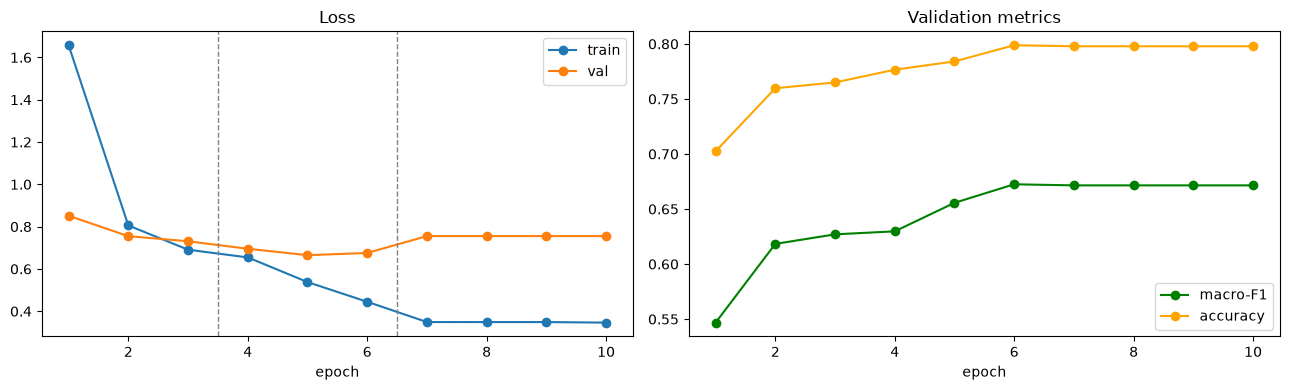

In [26]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(ep, history["train_loss"], "o-", label="train")
ax[0].plot(ep, history["val_loss"], "o-", label="val")
for b in (STAGE2_EPOCH + 0.5, STAGE3_EPOCH + 0.5):
    ax[0].axvline(b, ls="--", c="gray", lw=1)
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(ep, history["val_f1"], "o-", color="green", label="macro-F1")
ax[1].plot(ep, history["val_acc"], "o-", color="orange", label="accuracy")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

### Test evaluation

In [27]:
_bare(model).load_state_dict(torch.load(BEST_MODEL, map_location=device))

test_loss, test_f1, test_acc, test_preds, test_true = evaluate(test_loader)
print(f"Test accuracy : {test_acc:.4f}")
print(f"Test macro-F1 : {test_f1:.4f}\n")
print(classification_report(test_true, test_preds, target_names=[str(c) for c in le.classes_], digits=4))

Test accuracy : 0.7982
Test macro-F1 : 0.6710

              precision    recall  f1-score   support

    অন্যান্য     0.9426    0.6921    0.7981      8427
   ক্যাম্পাস     0.4804    0.8687    0.6187        99
        খেলা     0.9157    0.9820    0.9477      1948
       চাকরি     0.8036    0.8824    0.8411        51
       জাতীয়     0.7250    0.6550    0.6882      2194
         টেক     0.7190    0.8896    0.7952       489
        ধর্ম     0.5373    0.8571    0.6606        42
     প্রজন্ম     0.5630    0.7701    0.6505        87
      প্রবাস     0.6015    0.8811    0.7149       185
 প্রেস রিলিজ     0.1250    0.4444    0.1951         9
       ফিচার     0.5067    0.7732    0.6122       441
     বাণিজ্য     0.4741    0.8330    0.6043       473
      বিনোদন     0.8905    0.9353    0.9124      1330
 বিশ্ব সংবাদ     0.8808    0.9278    0.9037      2772
   ভিন্নচোখে     0.2768    0.5439    0.3669        57
       মতামত     0.5551    0.8866    0.6828       335
     রাজধানী     0.6108    0.7069 

c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2437 (\N{BENGALI LETTER A}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2472 (\N{BENGALI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2479 (\N{BENGALI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2478 (\N{BENGALI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\ProgramData\anaconda3\envs\2007058\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 2474 (\N{B

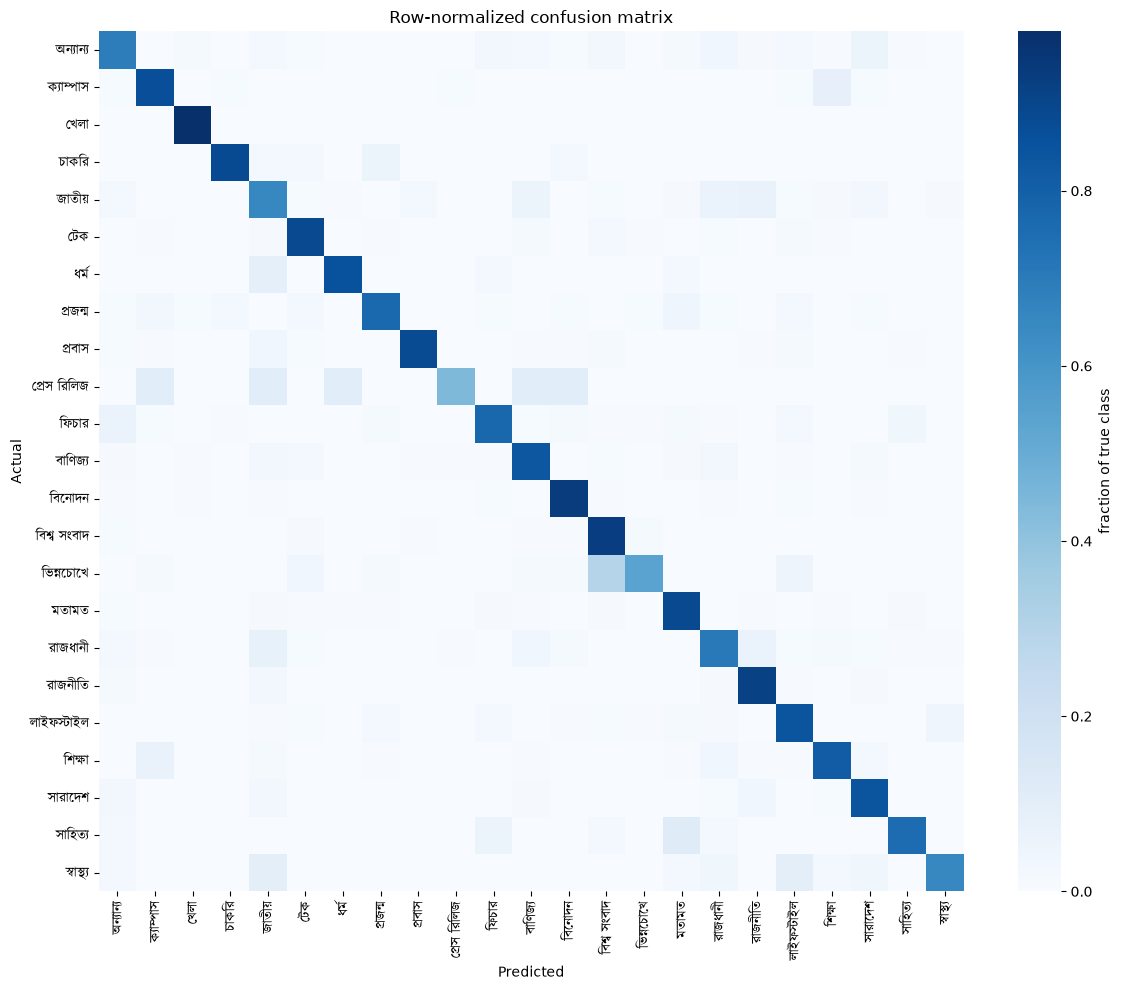

In [32]:
cm = confusion_matrix(test_true, test_preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

plt.figure(figsize=(12, 10))
ax = sns.heatmap(cm_norm, cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_,
                  cbar_kws={"label": "fraction of true class"})

ax.set_xticklabels(ax.get_xticklabels(), fontproperties=bengali_font, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), fontproperties=bengali_font, rotation=0)

plt.title("Row-normalized confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_22728\1831327792.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(ax.get_yticklabels(), fontproperties=bengali_font)


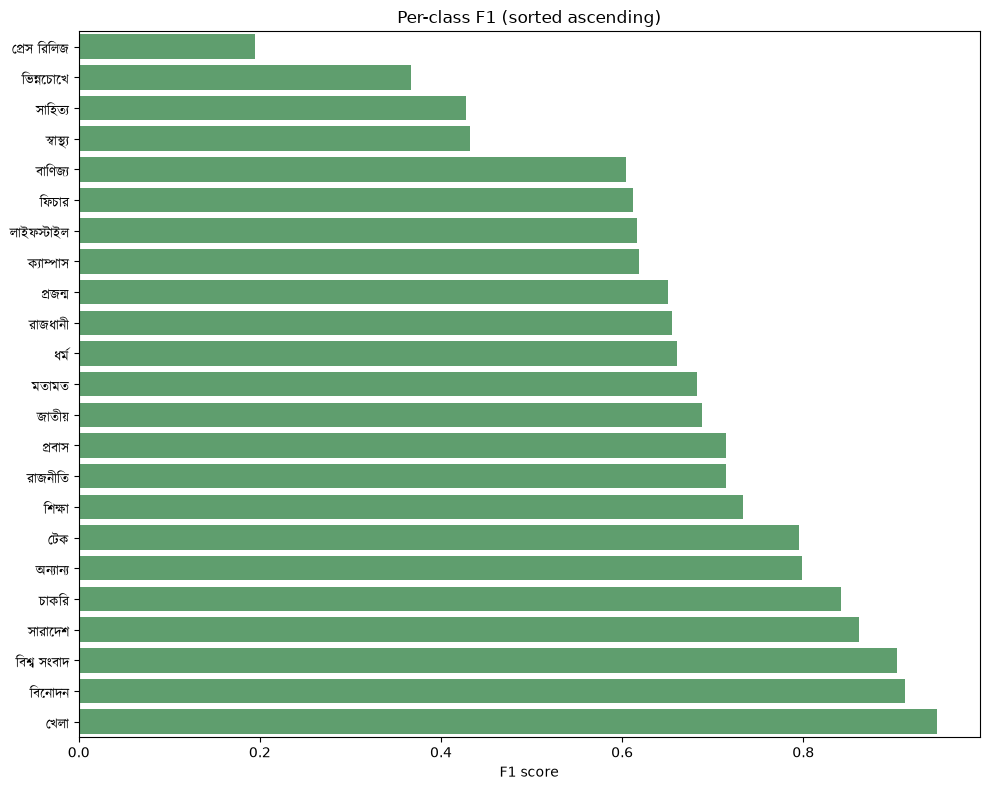

In [29]:
p, r, f, s = precision_recall_fscore_support(test_true, test_preds, labels=np.arange(num_labels), zero_division=0)
order = np.argsort(f)

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=f[order], y=np.array(le.classes_)[order], color="#55A868")
ax.set_yticklabels(ax.get_yticklabels(), fontproperties=bengali_font)

plt.title("Per-class F1 (sorted ascending)")
plt.xlabel("F1 score"); plt.tight_layout(); plt.show()

### Single-text inference

In [30]:
sample_text = ["বিয়ন্সে! পশ্চাত্যের সঙ্গীতে সুপারস্টার। গ্র্যামি অ্যাওয়ার্ডে সবচেয়ে বেশি পুরস্কার জেতার এক অনন্য রেকর্ড গড়েছেন এই মার্কিন গায়িকা।"]

def predict(texts):
    enc = tokenizer(texts, truncation=True, max_length=MAX_LEN, padding=True,
                     return_token_type_ids=False, return_tensors="pt")
    model.eval()
    with torch.no_grad(), autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
        logits = model(input_ids=enc["input_ids"].to(device), attention_mask=enc["attention_mask"].to(device)).logits
    probs = F.softmax(logits.float(), dim=1).cpu().numpy()
    return le.inverse_transform(probs.argmax(1)), probs

names, probs = predict(sample_text)
print("Predicted category:", names[0])
print("Confidence        : %.3f" % probs[0].max())

Predicted category: বিনোদন
Confidence        : 0.968


In [31]:
_bare(model).load_state_dict(torch.load(BEST_MODEL, map_location=device, weights_only=False))

id2label = {i: c for i, c in enumerate(le.classes_)}
label2id = {c: i for i, c in enumerate(le.classes_)}
_bare(model).config.id2label = id2label
_bare(model).config.label2id = label2id

EXPORT_DIR = "banglabert-news-classifier"
_bare(model).save_pretrained(EXPORT_DIR, safe_serialization=True)
tokenizer.save_pretrained(EXPORT_DIR)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.00it/s]


('banglabert-news-classifier\\tokenizer_config.json',
 'banglabert-news-classifier\\tokenizer.json')